# Explainability Analysis for Multimodal Breast Cancer Recurrence Prediction Model

## Overview

This notebook performs the explainability analysis of the developed multimodal Transformer-based survival prediction model for breast cancer recurrence risk prediction.

The trained model integrates three complementary data modalities:

1. **Clinical features**
   - Patient demographic information
   - Tumor characteristics
   - Pathological staging information
   - Treatment-related variables
   - Molecular subtype information

2. **Genomic features**
   - Selected gene expression features used for recurrence risk prediction

3. **Pathology features**
   - Deep feature representations extracted from histopathology image patches

The goal of this notebook is to provide model interpretability by identifying which features, modalities, and pathology regions contribute most to the model predictions.

---

# Explainability Methods Applied

## 1. SHAP-Based Feature Contribution Analysis

SHAP (SHapley Additive exPlanations) was applied separately to each tabular modality to quantify individual feature contributions to the model output.

### Clinical SHAP Analysis

The clinical branch of the model was explained by fixing genomic and pathology inputs while varying clinical features.

Outputs generated:

- Mean absolute SHAP feature importance
- Ranked list of the most influential clinical variables
- SHAP contribution values for individual patients
- Feature importance visualization

This analysis identifies which clinical characteristics have the strongest influence on recurrence risk prediction.

---

### Genomic SHAP Analysis

The genomic branch was explained by fixing clinical and pathology information while varying genomic features.

Outputs generated:

- Mean absolute SHAP importance for genes
- Ranked list of the most influential genes
- Patient-level genomic SHAP contribution values
- Gene importance visualization

This analysis highlights genes that contribute most to the Transformer survival prediction.

---

# 2. Transformer Attention Analysis

The internal attention mechanism of the multimodal Transformer was analyzed to understand how the model combines different modalities.

The attention extraction process evaluates:

- Clinical token attention
- Genomic token attention
- Pathology token attention

Outputs generated:

- Attention matrices from Transformer layers
- Modality-level attention visualization
- Attention heatmaps

This provides insight into how the model prioritizes different information sources during prediction.

---

# 3. Pathology Attention Visualization

The pathology Transformer encoder was analyzed to identify important histopathology image patches.

The attention mechanism assigns importance scores to individual image patches.

Outputs generated:

- Patch-level attention scores
- Ranking of the highest-attention pathology patches
- Top contributing patch table

These results indicate which regions of the histopathology representation receive the highest attention from the model.

---

# Model Explainability Outputs

The following explainability results are saved:

## SHAP Results

- Clinical SHAP feature importance table (.csv)
- Genomic SHAP feature importance table (.csv)
- Patient-level SHAP contribution values
- SHAP visualization figures

## Attention Results

- Transformer attention matrices
- Modality attention visualization
- Pathology patch attention table (.csv)
- Pathology attention figures

All results are stored in the explanation output directory for further analysis and inclusion in the Master's thesis.

---

# Purpose of Explainability Analysis

The explainability analysis demonstrates that the proposed multimodal Transformer model is not only capable of predicting breast cancer recurrence risk but also provides interpretable evidence regarding:

- Which clinical variables influence predictions
- Which genomic features contribute to risk estimation
- How the Transformer combines multimodal information
- Which pathology regions receive higher model attention

These analyses improve model transparency and support the clinical interpretability of the proposed AI framework.

##Imports

In [3]:
# ============================================================
# IMPORTS
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import shap

from tqdm import tqdm
from torch.utils.data import DataLoader

##Mount Google Drive

In [4]:
# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive mounted.")

Mounted at /content/drive
Google Drive mounted.


##Define Project Paths

In [5]:

# ============================================================
# PROJECT PATHS — CORRECTED LEAKAGE-FREE MASTER DATASET V2
# ============================================================

import os
import pandas as pd
import numpy as np

BASE_DIR = "/content/drive/MyDrive/TCGA_BRCA"

# NEW master dataset built from corrected splits and 200 genes
DATASET_DIR = os.path.join(
    BASE_DIR,
    "multimodal_rfs_dataset_leakage_free_v2"
)

# Pathology feature arrays
PATHOLOGY_DIR = os.path.join(
    BASE_DIR,
    "Features"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "trained_models_leakage_free_endpoint_v2"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "transformer_results_leakage_free_endpoint_v2"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Confirm the expected files exist before proceeding
required_files = [
    "master_rfs_train.csv",
    "master_rfs_validation.csv",
    "master_rfs_test.csv",
    "master_rfs_all.csv"
]

for filename in required_files:
    filepath = os.path.join(DATASET_DIR, filename)
    assert os.path.isfile(filepath), (
        f"Required master dataset file not found: {filepath}"
    )

print("Project paths ready.")
print("Master dataset:", DATASET_DIR)
print("Pathology directory:", PATHOLOGY_DIR)
print("Model outputs:", MODEL_DIR)
print("Results:", RESULT_DIR)
print("\nAll four new master dataset files exist.")


Project paths ready.
Master dataset: /content/drive/MyDrive/TCGA_BRCA/multimodal_rfs_dataset_leakage_free_v2
Pathology directory: /content/drive/MyDrive/TCGA_BRCA/Features
Model outputs: /content/drive/MyDrive/TCGA_BRCA/trained_models_leakage_free_endpoint_v2
Results: /content/drive/MyDrive/TCGA_BRCA/transformer_results_leakage_free_endpoint_v2

All four new master dataset files exist.


##Device Configuration

In [6]:
# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("="*70)
print("Running on:", DEVICE)
print("="*70)

Running on: cpu


##Load datasets

In [7]:

# ============================================================
# LOAD CORRECTED MASTER DATASETS — ENDPOINT V2
# ============================================================

train = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_train.csv")
)

validation = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_validation.csv")
)

test = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_test.csv")
)

print("TRAIN:", train.shape)
print("VALIDATION:", validation.shape)
print("TEST:", test.shape)

print("\nPatients per split:")
print(len(train), len(validation), len(test))

# Expected corrected split sizes
assert len(train) == 236, (
    f"Expected 236 training patients, got {len(train)}."
)
assert len(validation) == 49, (
    f"Expected 49 validation patients, got {len(validation)}."
)
assert len(test) == 52, (
    f"Expected 52 test patients, got {len(test)}."
)

# Patient IDs must be unique and splits must not overlap
for name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    assert df["patient_id"].notna().all(), (
        f"Missing patient IDs in {name}."
    )
    assert df["patient_id"].is_unique, (
        f"Duplicate patient IDs in {name}."
    )

assert set(train["patient_id"]).isdisjoint(
    validation["patient_id"]
)
assert set(train["patient_id"]).isdisjoint(
    test["patient_id"]
)
assert set(validation["patient_id"]).isdisjoint(
    test["patient_id"]
)

# Confirm the required survival targets exist and are valid
for name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    assert {"survival_time", "event"}.issubset(df.columns), (
        f"Survival target columns missing in {name}."
    )
    assert df["survival_time"].notna().all(), (
        f"Missing survival times in {name}."
    )
    assert (df["survival_time"] > 0).all(), (
        f"Invalid survival times in {name}."
    )
    assert df["event"].isin([0, 1]).all(), (
        f"Invalid event labels in {name}."
    )

print("\nEvent counts:")
for name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    print(name, df["event"].value_counts().sort_index().to_dict())

print("\nPASS: corrected master datasets loaded.")
print("PASS: splits do not overlap.")
print("PASS: authoritative survival targets are present.")


TRAIN: (236, 226)
VALIDATION: (49, 226)
TEST: (52, 226)

Patients per split:
236 49 52

Event counts:
train {0: 182, 1: 54}
validation {0: 37, 1: 12}
test {0: 40, 1: 12}

PASS: corrected master datasets loaded.
PASS: splits do not overlap.
PASS: authoritative survival targets are present.


In [38]:

# ============================================================
# DEFINE CLINICAL AND GENOMIC INPUT FEATURES — ENDPOINT V2
# ============================================================

non_feature_columns = [
    "patient_id",
    "file_uuid",
    "pathology_path",
    "split",
    "event",
    "survival_time"
]

clinical_columns = [
    "years_to_birth",
    "Tumor_purity",
    "pathologic_stage",
    "pathology_T_stage",
    "pathology_N_stage",
    "pathology_M_stage",
    "number_of_lymph_nodes",
    "radiation_therapy"
]

# Include the encoded clinical categorical features
clinical_columns += [
    c for c in train.columns
    if c.startswith((
        "histological_type",
        "PAM50",
        "race",
        "ethnicity"
    ))
]

# Check that all expected clinical features exist
missing_clinical = [
    c for c in clinical_columns
    if c not in train.columns
]

assert not missing_clinical, (
    f"Expected clinical features missing: {missing_clinical}"
)

# The master dataset should contain exactly 200 selected genes
# in addition to clinical features and metadata.
genomic_columns = [
    c for c in train.columns
    if c not in clinical_columns + non_feature_columns
]

print("Clinical features:", len(clinical_columns))
print("Genomic features:", len(genomic_columns))
print("Total tabular features:", len(clinical_columns) + len(genomic_columns))

assert len(genomic_columns) == 200, (
    f"Expected 200 genomic features from the new pipeline, "
    f"but found {len(genomic_columns)}. Check the master dataset."
)

assert not set(clinical_columns) & set(genomic_columns)
assert not set(non_feature_columns) & set(genomic_columns)

assert "event" not in clinical_columns + genomic_columns
assert "survival_time" not in clinical_columns + genomic_columns
assert "patient_id" not in clinical_columns + genomic_columns
assert "pathology_path" not in clinical_columns + genomic_columns

# Confirm the validation and test datasets have the same feature columns
for name, df in [
    ("validation", validation),
    ("test", test)
]:
    missing_features = [
        c for c in clinical_columns + genomic_columns
        if c not in df.columns
    ]
    assert not missing_features, (
        f"Features missing from {name}: {missing_features}"
    )

print("\nPASS: using the new master dataset.")
print("PASS: exactly 200 genomic features detected.")
print("PASS: survival targets and metadata excluded from inputs.")


Clinical features: 20
Genomic features: 200
Total tabular features: 220

PASS: using the new master dataset.
PASS: exactly 200 genomic features detected.
PASS: survival targets and metadata excluded from inputs.


##Define Feature Groups

In [9]:
# ============================================================
# DEFINE FEATURE GROUPS
# ============================================================


non_feature_columns = [
    "patient_id",
    "file_uuid",
    "event",
    "survival_time"
]

clinical_columns = [
    "years_to_birth",
    "Tumor_purity",
    "pathologic_stage",
    "pathology_T_stage",
    "pathology_N_stage",
    "pathology_M_stage",
    "number_of_lymph_nodes",
    "radiation_therapy"
]

clinical_columns += [
    c for c in train.columns
    if c.startswith((
        "histological_type",
        "PAM50",
        "race",
        "ethnicity"
    ))
]

genomic_columns = [
    c for c in train.columns
    if c not in clinical_columns + non_feature_columns
]

target_columns = [
    "event",
    "survival_time"
]

print("="*70)
print("FEATURE GROUPS")
print("="*70)

print("Clinical features:", len(clinical_columns))
print("Genomic features :", len(genomic_columns))

print("\nFirst clinical:")
print(clinical_columns[:5])

print("\nFirst genomic:")
print(genomic_columns[:5])

FEATURE GROUPS
Clinical features: 20
Genomic features : 202

First clinical:
['years_to_birth', 'Tumor_purity', 'pathologic_stage', 'pathology_T_stage', 'pathology_N_stage']

First genomic:
['split', 'PSCA', 'ZNF385B', 'MYBPC1', 'CALML5']


##Import PyTorch and create Dataset

In [10]:
# ============================================================
# MULTIMODAL PYTORCH DATASET
# ============================================================

# prepared the Dataset structure that will be used to provide data to the Transformer model.

import torch

from torch.utils.data import Dataset


class MultimodalBreastCancerDataset(Dataset):


    def __init__(
        self,
        dataframe
    ):

        self.data = dataframe.reset_index(drop=True)



    def __len__(self):

        return len(self.data)



    def __getitem__(
        self,
        idx
    ):

        row = self.data.iloc[idx]


        # ----------------------------
        # Clinical features
        # ----------------------------

        clinical = row[
            clinical_columns
        ].values.astype(np.float32)



        # ----------------------------
        # Genomic features
        # ----------------------------

        genomic = row[
            genomic_columns
        ].values.astype(np.float32)



        # ----------------------------
        # Pathology features
        # ----------------------------

        pathology, mask = load_pathology_features(
            row["file_uuid"],
            MAX_PATCHES
        )



        # ----------------------------
        # Labels
        # ----------------------------

        event = np.float32(
            row["event"]
        )


        survival = np.float32(
            row["survival_time"]
        )



        return {

            "clinical":
            torch.tensor(
                clinical
            ),


            "genomic":
            torch.tensor(
                genomic
            ),


            "pathology":
            torch.tensor(
                pathology
            ),


            "mask":
            torch.tensor(
                mask
            ),


            "label":
            torch.tensor(
                event
            ),


            "survival":
            torch.tensor(
                survival
            ),


            "event":
torch.tensor(
    event
)
        }

##Create datasets

In [11]:

# ============================================================
# CREATE TRAIN / VALIDATION / TEST DATASETS
# ============================================================
# Creates PyTorch datasets for training, validation, and testing.
# Eğitim, validation ve test verileri için PyTorch datasetleri oluşturuldu.
#
# Each dataset contains:
# - Clinical features
# - Genomic features
# - Pathology embeddings
# - Survival information
#
# Her veri bölümü model için uygun Tensor formatında hazırlandı.

train_dataset = MultimodalBreastCancerDataset(
    train
)


val_dataset = MultimodalBreastCancerDataset(
    validation
)


test_dataset = MultimodalBreastCancerDataset(
    test
)



print("="*70)

print("Train samples:",
      len(train_dataset))

print("Validation samples:",
      len(val_dataset))

print("Test samples:",
      len(test_dataset))

Train samples: 236
Validation samples: 49
Test samples: 52


##DataLoaders

In [12]:
test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    drop_last=False
)


##Model Config

In [26]:
# ============================================================
# MODEL CONFIGURATION
# ============================================================
# Defines the main parameters used by the multimodal Transformer model.

MODEL_CONFIG = {


    # feature sizes

    "clinical_dim": len(clinical_columns),

    "genomic_dim": 200,

    "pathology_dim": 512,


    # transformer architecture parameters

    "embed_dim": 128,

    "num_heads": 4,

    "num_layers": 2,


    # regularization settings

    "dropout": 0.3,


    # training parameters

    "batch_size": 4,

    "learning_rate": 1e-4,

    "epochs": 100

}



print("="*70)
print("MODEL CONFIGURATION")
print("="*70)


for k,v in MODEL_CONFIG.items():

    print(
        k,
        ":",
        v
    )

MODEL CONFIGURATION
clinical_dim : 20
genomic_dim : 200
pathology_dim : 512
embed_dim : 128
num_heads : 4
num_layers : 2
dropout : 0.3
batch_size : 4
learning_rate : 0.0001
epochs : 100


##Clinical Encoder

In [27]:
# ============================================================
# CLINICAL ENCODER
# ============================================================

# Converts clinical features into Transformer-compatible embeddings.

# The encoder:
# - Projects clinical features to shared embedding dimension.
# - Applies normalization and non-linear transformation.
# - Adds token dimension for Transformer input.


import torch
import torch.nn as nn



class ClinicalEncoder(nn.Module):


    def __init__(
        self,
        input_dim,
        embed_dim,
        dropout=0.3
    ):

        super().__init__()


        self.encoder = nn.Sequential(

            nn.Linear(
                input_dim,
                embed_dim
            ),

            nn.LayerNorm(
                embed_dim
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            )

        )



    def forward(
        self,
        x
    ):

        """
        x:
        [batch, clinical_features]

        output:
        [batch, 1, embedding]
        """


        x = self.encoder(x)


        # create token dimension

        x = x.unsqueeze(1)


        return x

##Genomic Encoder

In [28]:
# ============================================================
# GENOMIC ENCODER
# ============================================================

# Converts genomic features into Transformer-compatible embeddings.

# The encoder:
# - Projects genomic features into a shared embedding dimension.
# - Uses normalization and non-linear transformation.
# - Adds token dimension for Transformer input.

class GenomicEncoder(nn.Module):


    def __init__(
        self,
        input_dim,
        embed_dim,
        dropout=0.3
    ):

        super().__init__()



        self.encoder = nn.Sequential(

            nn.Linear(
                input_dim,
                256
            ),

            nn.LayerNorm(
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),


            nn.Linear(
                256,
                embed_dim
            ),

            nn.LayerNorm(
                embed_dim
            )

        )



    def forward(
        self,
        x
    ):


        x = self.encoder(x)


        x = x.unsqueeze(1)


        return x

##Pathology Transformer Encoder

In [29]:
class PathologyEncoder(nn.Module):
    def __init__(
        self, input_dim, embed_dim,
        num_heads, num_layers, dropout=0.3
    ):
        super().__init__()

        self.patch_projection = nn.Linear(input_dim, embed_dim)
        self.cls_token = nn.Parameter(
            torch.randn(1, 1, embed_dim)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x, mask=None):
        batch_size, num_patches, _ = x.shape

        x = self.patch_projection(x)

        cls_tokens = self.cls_token.expand(
            batch_size, -1, -1
        )
        x = torch.cat([cls_tokens, x], dim=1)

        padding_mask = None

        if mask is not None:
            if mask.shape != (batch_size, num_patches):
                raise ValueError(
                    f"Expected mask shape {(batch_size, num_patches)}, "
                    f"got {tuple(mask.shape)}"
                )

            # True means ignore this patch.
            # The CLS token must never be masked.
            patch_padding = (mask <= 0)
            cls_padding = torch.zeros(
                (batch_size, 1),
                dtype=torch.bool,
                device=x.device
            )
            padding_mask = torch.cat(
                [cls_padding, patch_padding.to(x.device)],
                dim=1
            )

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        x = self.norm(x[:, 0, :])
        return x.unsqueeze(1)

##The Fusion Module

In [30]:
# ============================================================
# MULTIMODAL FUSION TRANSFORMER
# ============================================================

# Combines clinical, genomic, and pathology embeddings into one

# Steps:
# - Receives one token from each modality encoder.
# - Concatenates three modality tokens.
# - Uses Transformer attention to learn interactions between modalities.
# - Applies normalization and pooling to obtain final patient embedding.


class MultimodalFusionTransformer(nn.Module):


    def __init__(
        self,
        embed_dim,
        num_heads,
        num_layers,
        dropout=0.3
    ):

        super().__init__()



        encoder_layer = nn.TransformerEncoderLayer(

            d_model=embed_dim,

            nhead=num_heads,

            dim_feedforward=embed_dim*4,

            dropout=dropout,

            batch_first=True,

            activation="gelu"

        )



        self.transformer = nn.TransformerEncoder(

            encoder_layer,

            num_layers=num_layers

        )



        self.norm = nn.LayerNorm(
            embed_dim
        )



    def forward(
        self,
        clinical_token,
        genomic_token,
        pathology_token
    ):


        """

        Inputs:

        clinical:
        [batch,1,128]


        genomic:
        [batch,1,128]


        pathology:
        [batch,1,128]



        Output:

        fused representation

        [batch,128]

        """



        # concatenate modality tokens

        x = torch.cat(

            [
                clinical_token,
                genomic_token,
                pathology_token
            ],

            dim=1

        )



        # now:

        # [batch,3,128]


        x = self.transformer(
            x
        )


        x = self.norm(x)



        # mean pooling over modalities

        x = x.mean(
            dim=1
        )


        return x

##Prediction Heads

In [31]:

# Converts the fused multimodal patient representation into a survival risk score.

# The head:
# - Reduces embedding dimension.
# - Applies non-linear transformation.
# - Outputs one risk score for each patient.
#
# The output is used with Cox proportional hazards loss for Relapse-Free Survival prediction.

class SurvivalPredictionHead(nn.Module):

    def __init__(
        self,
        embed_dim,
        dropout=0.3
    ):
        super().__init__()

        self.head = nn.Sequential(

            nn.Linear(
                embed_dim,
                64
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                64,
                1
            )
        )


    def forward(self, x):

        risk = self.head(x)

        return risk

##Create the Complete Model

In [32]:
# ============================================================
# COMPLETE MULTIMODAL TRANSFORMER
# ============================================================


class MultimodalTransformer(nn.Module):


    def __init__(
        self,
        config
    ):

        super().__init__()



        self.clinical_encoder = ClinicalEncoder(

            config["clinical_dim"],

            config["embed_dim"],

            config["dropout"]

        )



        self.genomic_encoder = GenomicEncoder(

            config["genomic_dim"],

            config["embed_dim"],

            config["dropout"]

        )



        self.pathology_encoder = PathologyEncoder(

            config["pathology_dim"],

            config["embed_dim"],

            config["num_heads"],

            config["num_layers"],

            config["dropout"]

        )



        self.fusion = MultimodalFusionTransformer(

            config["embed_dim"],

            config["num_heads"],

            config["num_layers"],

            config["dropout"]

        )



        self.survival_head = SurvivalPredictionHead(
            config["embed_dim"],
            config["dropout"]
        )




    def forward(
        self,
        clinical,
        genomic,
        pathology,
        mask=None,
        use_modalities=None
    ):


        # ---------------------------------
        # Default: use all modalities
        # ---------------------------------

        if use_modalities is None:

            use_modalities = {

                "clinical": True,

                "genomic": True,

                "pathology": True

            }



        # ---------------------------------
        # Clinical encoder
        # ---------------------------------

        clinical_token = self.clinical_encoder(
            clinical
        )


        if not use_modalities["clinical"]:

            clinical_token = torch.zeros_like(
                clinical_token
            )



        # ---------------------------------
        # Genomic encoder
        # ---------------------------------

        genomic_token = self.genomic_encoder(
            genomic
        )


        if not use_modalities["genomic"]:

            genomic_token = torch.zeros_like(
                genomic_token
            )



        # ---------------------------------
        # Pathology encoder
        # ---------------------------------

        pathology_token = self.pathology_encoder(
            pathology,
            mask
        )


        if not use_modalities["pathology"]:

            pathology_token = torch.zeros_like(
                pathology_token
            )



        # ---------------------------------
        # Fusion Transformer
        # ---------------------------------

        fused = self.fusion(

            clinical_token,

            genomic_token,

            pathology_token

        )



        # ---------------------------------
        # Prediction heads
        # ---------------------------------

        survival = self.survival_head(fused)



        return {


            "survival":
            survival,


            "features":
            fused

        }

In [33]:
# ============================================================
# CREATE MODEL ARCHITECTURE
# ============================================================

model = MultimodalTransformer(
    MODEL_CONFIG
)

model = model.to(DEVICE)


print("MODEL CREATED")

MODEL CREATED


##Create pathology loading configuration

In [40]:
# ============================================================
# PATHOLOGY CONFIGURATION
# ============================================================


PATHOLOGY_DIR = "/content/drive/MyDrive/TCGA_BRCA/Features"


MAX_PATCHES = 512
PATCH_FEATURES = 512


print("="*70)
print("PATHOLOGY CONFIGURATION")
print("="*70)

print("Directory:")
print(PATHOLOGY_DIR)

print()

print("Maximum patches per patient:", MAX_PATCHES)
print("Patch embedding dimension:", PATCH_FEATURES)

PATHOLOGY CONFIGURATION
Directory:
/content/drive/MyDrive/TCGA_BRCA/Features

Maximum patches per patient: 512
Patch embedding dimension: 512


##Create pathology processing function

In [41]:
import os
import hashlib
import numpy as np

def load_pathology_features(file_uuid, max_patches=512):
    path = os.path.join(PATHOLOGY_DIR, str(file_uuid) + ".npy")

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Pathology features not found: {path}"
        )

    features = np.load(path).astype(np.float32)

    if features.ndim != 2 or features.shape[1] != 512:
        raise ValueError(
            f"Expected [num_patches, 512], got {features.shape}"
        )

    if not np.isfinite(features).all():
        raise ValueError(
            f"Non-finite pathology features in {path}"
        )

    n_patches = features.shape[0]

    if n_patches > max_patches:
        # Stable seed for this patient; independent of Python's hash randomization.
        digest = hashlib.sha256(
            str(file_uuid).encode("utf-8")
        ).digest()
        seed = int.from_bytes(digest[:8], byteorder="big")

        rng = np.random.default_rng(seed)
        indices = rng.choice(
            n_patches,
            size=max_patches,
            replace=False
        )
        features = features[indices]
        mask = np.ones(max_patches, dtype=np.float32)

    elif n_patches < max_patches:
        padding = np.zeros(
            (max_patches - n_patches, 512),
            dtype=np.float32
        )
        features = np.concatenate([features, padding], axis=0)

        mask = np.concatenate([
            np.ones(n_patches, dtype=np.float32),
            np.zeros(max_patches - n_patches, dtype=np.float32)
        ])

    else:
        mask = np.ones(max_patches, dtype=np.float32)

    return features.astype(np.float32), mask.astype(np.float32)

##Load the trained model

In [42]:

checkpoint_path = "/content/drive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt"

# Load the complete checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

# Extract the model weights from the checkpoint dictionary
state_dict = checkpoint["model_state_dict"]

# Initialize the model using your existing configuration
model = MultimodalTransformer(MODEL_CONFIG)

# Load the correct model weights
model.load_state_dict(state_dict)

# Move the model to the selected device
model = model.to(DEVICE)

# Set evaluation mode
model.eval()

print("Model loaded successfully.")
print("Checkpoint:", checkpoint_path)
print("Saved epoch:", checkpoint.get("epoch", "Not available"))
print("Validation C-index:", checkpoint.get("val_cindex", "Not available"))


Model loaded successfully.
Checkpoint: /content/drive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
Saved epoch: 38
Validation C-index: 0.6782945736434108


In [43]:
batch = next(iter(test_loader))

clinical = batch["clinical"].to(DEVICE)

genomic = batch["genomic"].to(DEVICE)

pathology = batch["pathology"].to(DEVICE)

mask = batch["mask"].to(DEVICE)

In [44]:
print("Clinical :", clinical.shape)

print("Genomic :", genomic.shape)

print("Pathology :", pathology.shape)

print("Mask :", mask.shape)

Clinical : torch.Size([4, 20])
Genomic : torch.Size([4, 200])
Pathology : torch.Size([4, 512, 512])
Mask : torch.Size([4, 512])



##SHAP Wrapper Model

In [45]:
# ============================================================
# SHAP WRAPPER MODEL
# ============================================================

import torch
import torch.nn as nn


class SurvivalWrapper(nn.Module):

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(
        self,
        clinical,
        genomic,
        pathology,
        mask
    ):

        output = self.model(
            clinical,
            genomic,
            pathology,
            mask
        )

        return output["survival"]


##Create Wrapper Model

In [46]:
# ============================================================
# CREATE WRAPPED MODEL
# ============================================================

wrapped_model = SurvivalWrapper(model)

wrapped_model.eval()

print("="*70)
print("SHAP WRAPPER CREATED")
print("="*70)



SHAP WRAPPER CREATED



##Create Background Data

In [47]:
# ============================================================
# CREATE SHAP BACKGROUND DATA
# ============================================================

clinical_background = []
genomic_background = []
pathology_background = []
mask_background = []

for batch in test_loader:

    clinical_background.append(batch["clinical"])
    genomic_background.append(batch["genomic"])
    pathology_background.append(batch["pathology"])
    mask_background.append(batch["mask"])

clinical_background = torch.cat(clinical_background, dim=0)[:20]
genomic_background = torch.cat(genomic_background, dim=0)[:20]
pathology_background = torch.cat(pathology_background, dim=0)[:20]
mask_background = torch.cat(mask_background, dim=0)[:20]

background = {
    "clinical": clinical_background.to(DEVICE),
    "genomic": genomic_background.to(DEVICE),
    "pathology": pathology_background.to(DEVICE),
    "mask": mask_background.to(DEVICE)
}

print("=" * 70)
print("BACKGROUND CREATED")
print("=" * 70)

print(background["clinical"].shape)
print(background["genomic"].shape)
print(background["pathology"].shape)
print(background["mask"].shape)

BACKGROUND CREATED
torch.Size([20, 20])
torch.Size([20, 200])
torch.Size([20, 512, 512])
torch.Size([20, 512])


##Clinical SHAP

In [48]:
# ============================================================
# ROBUST CLINICAL SHAP WRAPPER
# ============================================================


class ClinicalSHAPWrapper(torch.nn.Module):

    def __init__(
        self,
        model,
        genomic_background,
        pathology_background,
        mask_background
    ):

        super().__init__()

        self.model = model

        self.genomic_background = genomic_background
        self.pathology_background = pathology_background
        self.mask_background = mask_background



    def forward(self, clinical):


        batch_size = clinical.shape[0]


        # Repeat fixed modalities to match SHAP batch size

        genomic = self.genomic_background[0].unsqueeze(0).repeat(
            batch_size,
            1
        )


        pathology = self.pathology_background[0].unsqueeze(0).repeat(
            batch_size,
            1,
            1
        )


        mask = self.mask_background[0].unsqueeze(0).repeat(
            batch_size,
            1
        )



        output = self.model(
            clinical,
            genomic,
            pathology,
            mask
        )


        return output["survival"]


##Fix Non-Clinical Inputs

In [49]:
# ============================================================
# CREATE CLINICAL SHAP MODEL
# ============================================================


clinical_model = ClinicalSHAPWrapper(
    model,
    background["genomic"],
    background["pathology"],
    background["mask"]
)


clinical_model = clinical_model.to(DEVICE)

clinical_model.eval()


print("="*70)
print("Clinical SHAP model ready")
print("="*70)

Clinical SHAP model ready


In [50]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [51]:
import torch

print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu



##Prepare Clinical Dara for SHAP

In [52]:
# ============================================================
# PREPARE CLINICAL DATA FOR SHAP
# ============================================================

# Background clinical samples
clinical_background = background["clinical"]


# Samples to explain
# Use first 20 test patients
clinical_explain = clinical_background[:20]


print("="*70)
print("CLINICAL SHAP DATA")
print("="*70)

print(
    "Background:",
    clinical_background.shape
)

print(
    "Explain:",
    clinical_explain.shape
)

CLINICAL SHAP DATA
Background: torch.Size([20, 20])
Explain: torch.Size([20, 20])



##Create Clinical SHAP Explainer

In [53]:
# ============================================================
# CREATE CLINICAL SHAP EXPLAINER
# ============================================================

import shap


clinical_explainer = shap.GradientExplainer(
    clinical_model,
    clinical_background
)


print("="*70)
print("CLINICAL SHAP EXPLAINER CREATED")
print("="*70)



CLINICAL SHAP EXPLAINER CREATED



##Compute Clinical SHAP Values

In [54]:
# ============================================================
# COMPUTE CLINICAL SHAP VALUES
# ============================================================


clinical_shap_values = clinical_explainer.shap_values(
    clinical_explain
)


print("="*70)
print("CLINICAL SHAP VALUES COMPUTED")
print("="*70)


print(
    type(clinical_shap_values)
)


print(
    np.array(clinical_shap_values).shape
)

CLINICAL SHAP VALUES COMPUTED
<class 'numpy.ndarray'>
(20, 20, 1)


##Convert SHAP output

In [55]:
# ============================================================
# FORMAT SHAP OUTPUT
# ============================================================

if isinstance(clinical_shap_values, list):

    clinical_shap_values = clinical_shap_values[0]


clinical_shap_values = np.array(
    clinical_shap_values
)


print(
    clinical_shap_values.shape
)

(20, 20, 1)


##Create Feature Dataframe

In [56]:
# ============================================================
# CLINICAL FEATURE DATAFRAME
# ============================================================


# Remove output dimension
# (samples, features, 1) -> (samples, features)

clinical_shap_values_2d = clinical_shap_values[:,:,0]



clinical_explain_df = pd.DataFrame(
    clinical_explain.cpu().numpy(),
    columns=clinical_columns
)



clinical_shap_df = pd.DataFrame(
    clinical_shap_values_2d,
    columns=clinical_columns
)



print("="*70)
print("CLINICAL SHAP DATAFRAMES CREATED")
print("="*70)


print("Clinical data:")
display(clinical_explain_df.head())


print("\nSHAP values:")
display(clinical_shap_df.head())

CLINICAL SHAP DATAFRAMES CREATED
Clinical data:


,years_to_birth,Tumor_purity,pathologic_stage,pathology_T_stage,pathology_N_stage,pathology_M_stage,number_of_lymph_nodes,radiation_therapy,histological_type_infiltratinglobularcarcinoma,histological_type_medullarycarcinoma,histological_type_metaplasticcarcinoma,histological_type_mixedhistology(pleasespecify),histological_type_mucinouscarcinoma,"histological_type_other,specify",PAM50_Her2,PAM50_LumA,PAM50_LumB,race_blackorafricanamerican,race_white,ethnicity_nothispanicorlatino
0,0.280422,0.574052,2.0,3.0,0.0,0.0,-0.564417,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
1,-1.497203,-1.296419,2.0,2.0,0.0,0.0,-0.564417,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
2,-1.426098,-0.120498,3.0,3.0,2.0,0.0,0.538721,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
3,-0.501733,0.010160,2.0,2.0,1.0,0.0,-0.123162,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
4,1.346997,-0.304641,1.0,1.0,0.0,0.0,-0.564417,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0



SHAP values:


,years_to_birth,Tumor_purity,pathologic_stage,pathology_T_stage,pathology_N_stage,pathology_M_stage,number_of_lymph_nodes,radiation_therapy,histological_type_infiltratinglobularcarcinoma,histological_type_medullarycarcinoma,histological_type_metaplasticcarcinoma,histological_type_mixedhistology(pleasespecify),histological_type_mucinouscarcinoma,"histological_type_other,specify",PAM50_Her2,PAM50_LumA,PAM50_LumB,race_blackorafricanamerican,race_white,ethnicity_nothispanicorlatino
0,0.000835,0.006671,0.005943,0.044302,-0.026203,0.0,-0.013934,0.037461,-0.038898,0.0,0.0,0.0,0.0,0.0,-0.008587,-0.035748,0.003076,-0.003395,-0.002488,0.0
1,-0.017672,-0.022875,0.009476,0.009015,-0.021026,0.0,-0.013522,0.024423,0.007867,0.0,0.0,0.0,0.0,0.0,-0.009094,0.029567,-0.006208,-0.003402,-0.004463,0.0
2,-0.005461,0.003831,0.020281,0.015242,0.064226,0.0,0.061483,-0.008539,0.009434,0.0,0.0,0.0,0.0,0.0,-0.008393,0.028329,0.008486,-0.002533,-0.005155,0.0
3,-0.002213,0.007969,0.007639,0.006380,0.025805,0.0,0.018765,-0.008278,0.004510,0.0,0.0,0.0,0.0,0.0,-0.010851,0.029682,-0.018083,-0.003416,-0.005956,0.0
4,0.015344,-0.000029,-0.017312,-0.032416,-0.028320,0.0,-0.015456,0.060214,0.012599,0.0,0.0,0.0,0.0,0.0,-0.007600,-0.034589,0.008392,-0.004408,-0.005997,0.0



##Clinical SHAP Summary Plot

/tmp/ipykernel_1314/101773423.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(


<Figure size 1000x600 with 0 Axes>

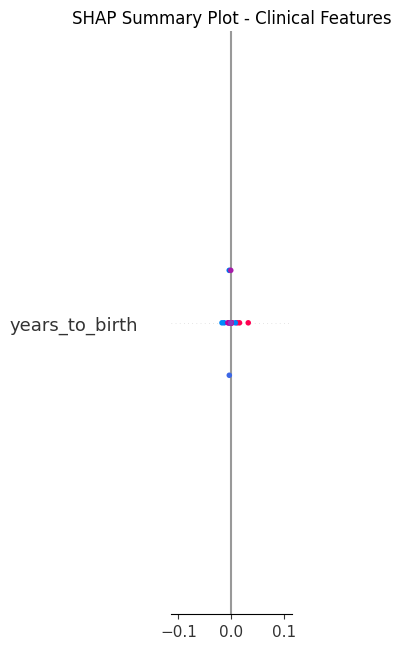

In [57]:
# ============================================================
# CLINICAL SHAP SUMMARY PLOT
# ============================================================


plt.figure(figsize=(10,6))


shap.summary_plot(
    clinical_shap_values,
    clinical_explain_df,
    feature_names=clinical_columns,
    show=False
)


plt.title(
    "SHAP Summary Plot - Clinical Features"
)


plt.tight_layout()


plt.savefig(
    "clinical_SHAP_summary.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


##Clinical SHAP Bar Importance

/tmp/ipykernel_1314/1504912926.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(


<Figure size 800x600 with 0 Axes>

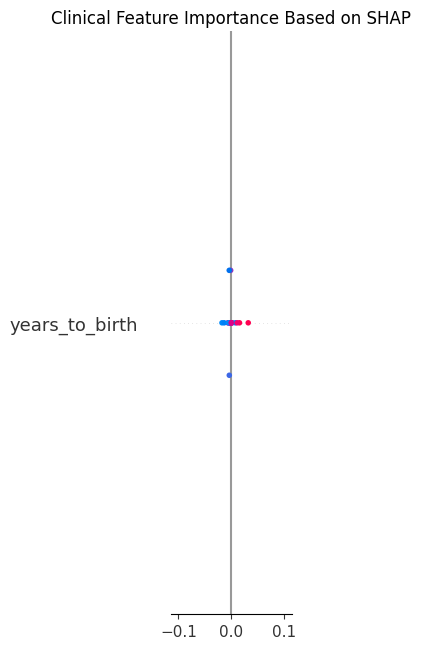

In [58]:
# ============================================================
# CLINICAL SHAP BAR IMPORTANCE
# ============================================================


plt.figure(figsize=(8,6))


shap.summary_plot(
    clinical_shap_values,
    clinical_explain_df,
    plot_type="bar",
    show=False
)


plt.title(
    "Clinical Feature Importance Based on SHAP"
)


plt.tight_layout()


plt.savefig(
    "clinical_SHAP_importance.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

##Top Features Table

In [59]:
# ============================================================
# TOP CLINICAL SHAP FEATURES
# ============================================================


# Remove output dimension
# (samples, features, 1) -> (samples, features)

clinical_shap_values_2d = clinical_shap_values[:,:,0]



importance = np.abs(
    clinical_shap_values_2d
).mean(axis=0)



shap_importance_df = pd.DataFrame({

    "Feature": clinical_columns,

    "Mean |SHAP|": importance

})



shap_importance_df = shap_importance_df.sort_values(
    "Mean |SHAP|",
    ascending=False
)



print("="*70)
print("TOP CLINICAL SHAP FEATURES")
print("="*70)


display(
    shap_importance_df.head(10)
)

TOP CLINICAL SHAP FEATURES


,Feature,Mean |SHAP|
15,PAM50_LumA,0.037294
4,pathology_N_stage,0.036514
6,number_of_lymph_nodes,0.019940
7,radiation_therapy,0.018675
3,pathology_T_stage,0.016040
14,PAM50_Her2,0.016010
8,histological_type_infiltratinglobularcarcinoma,0.015283
2,pathologic_stage,0.012711
1,Tumor_purity,0.008250
18,race_white,0.007087



##Genomic SHAP Wrapper Class

In [60]:
# ============================================================
# GENOMIC SHAP WRAPPER
# ============================================================

import torch
import torch.nn as nn


class GenomicSHAPWrapper(nn.Module):

    def __init__(
        self,
        model,
        fixed_clinical,
        fixed_pathology,
        fixed_mask
    ):

        super().__init__()

        self.model = model

        self.fixed_clinical = fixed_clinical
        self.fixed_pathology = fixed_pathology
        self.fixed_mask = fixed_mask



    def forward(self, genomic):


        batch_size = genomic.size(0)


        clinical = self.fixed_clinical

        pathology = self.fixed_pathology

        mask = self.fixed_mask



        if clinical.size(0) != batch_size:

            repeat_factor = (
                batch_size // clinical.size(0)
            ) + 1


            clinical = clinical.repeat(
                repeat_factor,
                1
            )[:batch_size]


            pathology = pathology.repeat(
                repeat_factor,
                1,
                1
            )[:batch_size]


            mask = mask.repeat(
                repeat_factor,
                1
            )[:batch_size]



        output = self.model(
            clinical,
            genomic,
            pathology,
            mask
        )


        risk = output["survival"]


        if risk.dim() == 1:
            risk = risk.unsqueeze(1)


        return risk

##Prepare Fixed Inputs

In [61]:
# ============================================================
# FIX NON-GENOMIC INPUTS FOR GENOMIC SHAP
# ============================================================


NUM_BACKGROUND = 20


fixed_clinical_genomic = background["clinical"][:NUM_BACKGROUND]

fixed_pathology_genomic = background["pathology"][:NUM_BACKGROUND]

fixed_mask_genomic = background["mask"][:NUM_BACKGROUND]

fixed_genomic = background["genomic"][:NUM_BACKGROUND]



print("="*70)
print("FIXED GENOMIC SHAP BACKGROUND")
print("="*70)


print("Clinical :", fixed_clinical_genomic.shape)

print("Genomic :", fixed_genomic.shape)

print("Pathology :", fixed_pathology_genomic.shape)

print("Mask :", fixed_mask_genomic.shape)

FIXED GENOMIC SHAP BACKGROUND
Clinical : torch.Size([20, 20])
Genomic : torch.Size([20, 200])
Pathology : torch.Size([20, 512, 512])
Mask : torch.Size([20, 512])


##Create Genomic SHAP Wrapper

In [62]:
# ============================================================
# CREATE GENOMIC SHAP WRAPPER
# ============================================================


genomic_model = GenomicSHAPWrapper(
    model,
    fixed_clinical_genomic,
    fixed_pathology_genomic,
    fixed_mask_genomic
)


genomic_model = genomic_model.to(DEVICE)

genomic_model.eval()


print("="*70)
print("GENOMIC SHAP MODEL READY")
print("="*70)

GENOMIC SHAP MODEL READY


##Create Genomic Background

In [63]:
# ============================================================
# GENOMIC BACKGROUND
# ============================================================



genomic_background = fixed_genomic

print("="*70)
print("GENOMIC BACKGROUND CREATED")
print("="*70)


print(
    genomic_background.shape
)

GENOMIC BACKGROUND CREATED
torch.Size([20, 200])


##Create SHAP Explainer

In [64]:
# ============================================================
# CREATE GENOMIC SHAP EXPLAINER
# ============================================================


genomic_explainer = shap.GradientExplainer(
    genomic_model,
    genomic_background
)


print("="*70)
print("GENOMIC SHAP EXPLAINER CREATED")
print("="*70)


GENOMIC SHAP EXPLAINER CREATED


##Select Samples To Explain

In [65]:
# ============================================================
# GENOMIC EXPLANATION DATA
# ============================================================


# collect genomic features from test loader

all_test_genomic = []


with torch.no_grad():

    for batch in test_loader:

        genomic = batch["genomic"]

        all_test_genomic.append(
            genomic
        )


test_genomic = torch.cat(
    all_test_genomic,
    dim=0
)



# take first 20 samples

genomic_explain = test_genomic[:20].to(DEVICE)



print("="*70)
print("GENOMIC EXPLANATION DATA CREATED")
print("="*70)


print(
    genomic_explain.shape
)

GENOMIC EXPLANATION DATA CREATED
torch.Size([20, 200])


##Compute Genomic SHAP Values

In [66]:
# ============================================================
# COMPUTE GENOMIC SHAP VALUES
# ============================================================


genomic_shap_values = genomic_explainer.shap_values(
    genomic_explain
)



print("="*70)
print("GENOMIC SHAP VALUES COMPUTED")
print("="*70)


print(
    type(genomic_shap_values)
)


print(
    np.array(genomic_shap_values).shape
)

GENOMIC SHAP VALUES COMPUTED
<class 'numpy.ndarray'>
(20, 200, 1)


##Fix SHAP Dimensions

In [67]:
# ============================================================
# FIX SHAP DIMENSIONS
# ============================================================


if genomic_shap_values.ndim == 3:

    genomic_shap_values = np.squeeze(
        genomic_shap_values,
        axis=-1
    )


print(
    genomic_shap_values.shape
)

(20, 200)


##Create Genomic SHAP DataFrame

In [68]:
# ============================================================
# GENOMIC SHAP DATAFRAME
# ============================================================


genomic_explain_df = pd.DataFrame(
    genomic_explain.cpu().numpy(),
    columns=genomic_columns
)



genomic_shap_df = pd.DataFrame(
    genomic_shap_values,
    columns=genomic_columns
)



print("="*70)
print("GENOMIC SHAP DATAFRAMES CREATED")
print("="*70)



print(
    genomic_explain_df.head()
)


print(
    genomic_shap_df.head()
)

GENOMIC SHAP DATAFRAMES CREATED
       PSCA   ZNF385B    MYBPC1    CALML5     PRAME      FLT3     GREB1  \
0  0.592377  1.673197  0.606413  1.108824 -0.886871 -1.328742 -1.201020   
1 -0.402548 -0.482827 -1.109688  1.392738 -0.624837  1.400786  0.860189   
2  0.289083 -1.076894 -0.956039  1.686623 -0.979083 -1.944526 -2.462502   
3 -0.172281  1.798992  0.196942 -1.378213  0.628918  1.037590  0.946703   
4 -0.666334  0.150132  1.493841  0.088020 -0.068853 -0.855467 -0.069489   

     TSPAN8     IL6ST    TUBA3E  ...      ABP1   PCDHA13   C5orf46      VWA2  \
0 -0.915137  1.009484 -0.515685  ... -1.127527 -0.456780 -1.961448  1.253667   
1  1.281583 -0.575039  1.094257  ...  0.659256 -1.182480 -1.258978 -1.839122   
2 -1.062788 -0.831307 -1.264198  ... -0.615419 -0.329953  0.681990 -0.389300   
3 -1.062788 -0.005295 -0.775283  ... -0.429901 -0.200057  0.555849  0.844397   
4  1.442756  1.337060  0.475659  ... -0.785830  0.393950 -0.738658  0.982440   

   C6orf141     RPS28      MUC2    S

##Top Genomic Features

In [69]:
# ============================================================
# TOP GENOMIC SHAP FEATURES
# ============================================================


genomic_importance = np.abs(
    genomic_shap_values
).mean(axis=0)



genomic_importance_df = pd.DataFrame({

    "Feature": genomic_columns,

    "Mean |SHAP|": genomic_importance

})



genomic_importance_df = genomic_importance_df.sort_values(
    "Mean |SHAP|",
    ascending=False
)



print("="*70)
print("TOP GENOMIC SHAP FEATURES")
print("="*70)



display(
    genomic_importance_df.head(20)
)

TOP GENOMIC SHAP FEATURES


,Feature,Mean |SHAP|
17,C1orf173,0.017724
77,KCNK3,0.017674
61,LYPD6,0.017146
1,ZNF385B,0.016778
131,DLGAP1,0.016316
163,TMEM84,0.016171
6,GREB1,0.016152
112,ELOVL2,0.016052
105,KCNE4,0.014950
24,FAM5C,0.014727


##Plot Top 20 Genomic Features

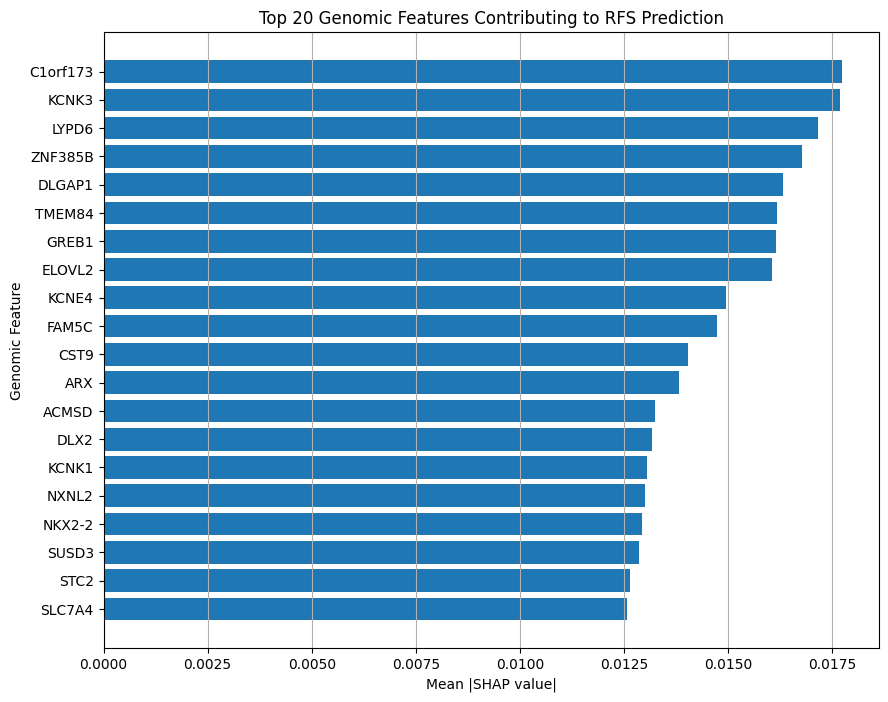

In [70]:
# ============================================================
# GENOMIC SHAP IMPORTANCE PLOT
# ============================================================


top20 = genomic_importance_df.head(20)


plt.figure(figsize=(10,8))


plt.barh(
    top20["Feature"][::-1],
    top20["Mean |SHAP|"][::-1]
)


plt.xlabel(
    "Mean |SHAP value|"
)


plt.ylabel(
    "Genomic Feature"
)


plt.title(
    "Top 20 Genomic Features Contributing to RFS Prediction"
)


plt.grid(
    axis="x"
)


plt.show()

##Transformer Attention Analysis

##Create Attention Extraction Layer

In [71]:
# ============================================================
# ATTENTION EXTRACTION TRANSFORMER
# ============================================================


class AttentionFusionTransformer(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        num_layers,
        dropout=0.3
    ):
        super().__init__()


        self.layers = nn.ModuleList()


        for _ in range(num_layers):

            self.layers.append(
                nn.MultiheadAttention(
                    embed_dim,
                    num_heads,
                    dropout=dropout,
                    batch_first=True
                )
            )


        self.norm = nn.LayerNorm(embed_dim)


        self.attention_weights = None



    def forward(
        self,
        clinical_token,
        genomic_token,
        pathology_token
    ):


        x = torch.cat(
            [
                clinical_token,
                genomic_token,
                pathology_token
            ],
            dim=1
        )


        for attn in self.layers:

            x, weights = attn(
                x,
                x,
                x,
                need_weights=True,
                average_attn_weights=False
            )


            self.attention_weights = weights



        x = self.norm(x)


        x = x.mean(dim=1)


        return x

##Replace Fusion With Attention Version

In [73]:

# ============================================================
# CREATE ATTENTION MODEL
# ============================================================

# Load the full checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

# Extract the trained model weights
state_dict = checkpoint["model_state_dict"]

# Create the model using the corrected configuration
attention_model = MultimodalTransformer(MODEL_CONFIG)

# Load the trained weights
attention_model.load_state_dict(state_dict)

# Move model to device and set evaluation mode
attention_model = attention_model.to(DEVICE)
attention_model.eval()

print("=" * 70)
print("ATTENTION MODEL READY")
print("Checkpoint epoch:", checkpoint.get("epoch", "Not available"))
print("Validation C-index:", checkpoint.get("val_cindex", "Not available"))
print("=" * 70)


ATTENTION MODEL READY
Checkpoint epoch: 38
Validation C-index: 0.6782945736434108


##Replace Fusion Module

In [74]:
attention_model.fusion = AttentionFusionTransformer(
    MODEL_CONFIG["embed_dim"],
    MODEL_CONFIG["num_heads"],
    MODEL_CONFIG["num_layers"],
    MODEL_CONFIG["dropout"]
)


print("Fusion replaced with attention extractor")

Fusion replaced with attention extractor


##Get One Patient

In [75]:
# ============================================================
# SELECT PATIENT FOR ATTENTION
# ============================================================


batch = next(iter(test_loader))


clinical = batch["clinical"].to(DEVICE)

genomic = batch["genomic"].to(DEVICE)

pathology = batch["pathology"].to(DEVICE)

mask = batch["mask"].to(DEVICE)



print(clinical.shape)
print(genomic.shape)
print(pathology.shape)

torch.Size([4, 20])
torch.Size([4, 200])
torch.Size([4, 512, 512])


##Run Attention

In [76]:
# ============================================================
# EXTRACT ATTENTION
# ============================================================


with torch.no_grad():

    output = attention_model(
        clinical,
        genomic,
        pathology,
        mask
    )


attention_weights = (
    attention_model.fusion.attention_weights
)



print("="*70)
print("ATTENTION EXTRACTED")
print("="*70)


print(
    attention_weights.shape
)

ATTENTION EXTRACTED
torch.Size([4, 4, 3, 3])


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


##Average Attention

In [77]:
# ============================================================
# AVERAGE ATTENTION
# ============================================================


attention_matrix = attention_weights.mean(
    dim=1
)


attention_matrix = attention_matrix.mean(
    dim=0
)


print(attention_matrix)

tensor([[0.3570, 0.4162, 0.2981],
        [0.3279, 0.2964, 0.2975],
        [0.4188, 0.3560, 0.2648]])


##Plot Modality Attention

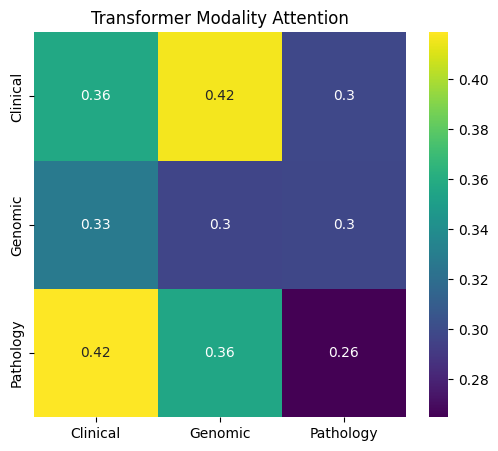

In [78]:
# ============================================================
# MODALITY ATTENTION HEATMAP
# ============================================================


import seaborn as sns


modalities = [
    "Clinical",
    "Genomic",
    "Pathology"
]


plt.figure(
    figsize=(6,5)
)


sns.heatmap(
    attention_matrix.cpu().numpy(),
    annot=True,
    xticklabels=modalities,
    yticklabels=modalities,
    cmap="viridis"
)


plt.title(
    "Transformer Modality Attention"
)


plt.show()

##Pathology Attention Visualization

##Create Pathology Attention Extractor

In [79]:
# ============================================================
# PATHOLOGY ATTENTION EXTRACTOR
# ============================================================


class PathologyAttentionExtractor(nn.Module):

    def __init__(self, pathology_encoder):

        super().__init__()

        self.pathology_encoder = pathology_encoder


    def forward(self, x, mask=None):

        """
        x:
        [batch, patches, 512]

        output:
        patch embeddings + attention weights
        """


        batch_size = x.size(0)


        # project patches

        x = self.pathology_encoder.patch_projection(x)


        # add CLS token

        cls_tokens = self.pathology_encoder.cls_token.expand(
            batch_size,
            -1,
            -1
        )


        x = torch.cat(
            [
                cls_tokens,
                x
            ],
            dim=1
        )


        # ---------------------------------
        # manually extract attention
        # ---------------------------------

        attention_weights = []


        for layer in self.pathology_encoder.transformer.layers:


            attn_output, attn = layer.self_attn(
                x,
                x,
                x,
                need_weights=True,
                average_attn_weights=False
            )


            attention_weights.append(
                attn
            )


            x = layer.norm1(
                x + attn_output
            )


            x = layer.norm2(
                x + layer.linear2(
                    layer.dropout(
                        layer.activation(
                            layer.linear1(x)
                        )
                    )
                )
            )


        x = self.pathology_encoder.norm(x)


        return x, attention_weights



print("="*70)
print("PATHOLOGY ATTENTION EXTRACTOR CREATED")
print("="*70)

PATHOLOGY ATTENTION EXTRACTOR CREATED


##Create Attention Model

In [80]:
# ============================================================
# CREATE PATHOLOGY ATTENTION MODEL
# ============================================================


pathology_attention_model = PathologyAttentionExtractor(
    model.pathology_encoder
)


pathology_attention_model = pathology_attention_model.to(
    DEVICE
)


pathology_attention_model.eval()


print("="*70)
print("PATHOLOGY ATTENTION MODEL READY")
print("="*70)

PATHOLOGY ATTENTION MODEL READY


##Get One Patient Pathology Data

In [81]:
# ============================================================
# SELECT PATIENT PATHOLOGY
# ============================================================


batch = next(iter(test_loader))


pathology = batch["pathology"].to(
    DEVICE
)


mask = batch["mask"].to(
    DEVICE
)


print("="*70)
print("PATHOLOGY SAMPLE")
print("="*70)


print(
    "Pathology:",
    pathology.shape
)


print(
    "Mask:",
    mask.shape
)

PATHOLOGY SAMPLE
Pathology: torch.Size([4, 512, 512])
Mask: torch.Size([4, 512])


##Extract Patch Attention

In [82]:
# ============================================================
# EXTRACT PATHOLOGY ATTENTION
# ============================================================


with torch.no_grad():

    encoded, attention_weights = pathology_attention_model(
        pathology,
        mask
    )


print("="*70)
print("PATHOLOGY ATTENTION EXTRACTED")
print("="*70)


print(
    "Encoded:",
    encoded.shape
)


print(
    "Number of layers:",
    len(attention_weights)
)


print(
    "Attention shape:",
    attention_weights[0].shape
)

PATHOLOGY ATTENTION EXTRACTED
Encoded: torch.Size([4, 513, 128])
Number of layers: 2
Attention shape: torch.Size([4, 4, 513, 513])


##Extract Patch Importance Scores

In [83]:
# ============================================================
# COMPUTE PATCH IMPORTANCE
# ============================================================


# use last transformer layer

last_attention = attention_weights[-1]


# average heads

attention_mean = last_attention.mean(
    dim=1
)


# CLS token attention to patches

patch_attention = attention_mean[:,0,1:]


print("="*70)
print("PATCH ATTENTION SCORES")
print("="*70)


print(
    patch_attention.shape
)

PATCH ATTENTION SCORES
torch.Size([4, 512])


##Rank Important Patches

In [84]:
# ============================================================
# TOP IMPORTANT PATCHES
# ============================================================


patient_id = 0


scores = patch_attention[
    patient_id
]


top_k = 20


top_values, top_indices = torch.topk(
    scores,
    k=top_k
)


print("="*70)
print("TOP PATHOLOGY PATCHES")
print("="*70)


for i in range(top_k):

    print(
        f"Patch {top_indices[i].item()}",
        "Attention:",
        round(
            top_values[i].item(),
            4
        )
    )

TOP PATHOLOGY PATCHES
Patch 321 Attention: 0.0028
Patch 101 Attention: 0.0026
Patch 325 Attention: 0.0026
Patch 306 Attention: 0.0025
Patch 429 Attention: 0.0025
Patch 200 Attention: 0.0024
Patch 86 Attention: 0.0024
Patch 460 Attention: 0.0024
Patch 183 Attention: 0.0023
Patch 283 Attention: 0.0023
Patch 427 Attention: 0.0023
Patch 448 Attention: 0.0023
Patch 175 Attention: 0.0023
Patch 382 Attention: 0.0023
Patch 174 Attention: 0.0023
Patch 81 Attention: 0.0023
Patch 223 Attention: 0.0023
Patch 21 Attention: 0.0023
Patch 402 Attention: 0.0023
Patch 79 Attention: 0.0023


##Visualize Attention Distribution

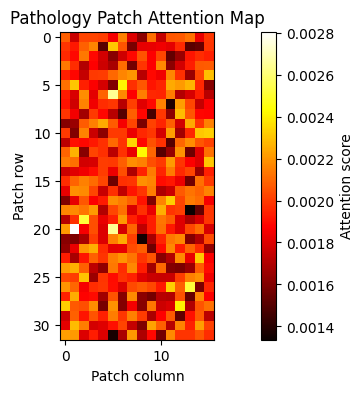

In [85]:
# ============================================================
# PATHOLOGY ATTENTION HEATMAP
# ============================================================


plt.figure(
    figsize=(12,4)
)


plt.imshow(
    scores.cpu().numpy().reshape(32,16),
    cmap="hot"
)


plt.colorbar(
    label="Attention score"
)


plt.title(
    "Pathology Patch Attention Map"
)


plt.xlabel(
    "Patch column"
)


plt.ylabel(
    "Patch row"
)


plt.show()


# ============================================================
# SAVE EXPLAINABILITY RESULTS - VERSION 1
# ============================================================


In [86]:
# ============================================================
# CREATE EXPLAINABILITY RESULTS FOLDER
# ============================================================

import os

EXPLAIN_DIR = "/content/drive/MyDrive/TCGA_BRCA/explainability_results_v1"

os.makedirs(
    EXPLAIN_DIR,
    exist_ok=True
)


print("="*70)
print("SAVE DIRECTORY CREATED")
print("="*70)

print(EXPLAIN_DIR)

SAVE DIRECTORY CREATED
/content/drive/MyDrive/TCGA_BRCA/explainability_results_v1


In [87]:
# ============================================================
# SAVE CLINICAL SHAP IMPORTANCE
# ============================================================

clinical_shap_path = os.path.join(
    EXPLAIN_DIR,
    "clinical_SHAP_feature_importance.csv"
)


shap_importance_df.to_csv(
    clinical_shap_path,
    index=False
)


print("Saved:")
print(clinical_shap_path)

Saved:
/content/drive/MyDrive/TCGA_BRCA/explainability_results_v1/clinical_SHAP_feature_importance.csv


In [88]:
# ============================================================
# CREATE GENOMIC SHAP IMPORTANCE TABLE
# ============================================================


# Remove extra output dimension if exists
genomic_shap_array = np.array(
    genomic_shap_values
)


print("Original SHAP shape:")
print(genomic_shap_array.shape)



if genomic_shap_array.ndim == 3:

    genomic_shap_array = genomic_shap_array.squeeze(-1)



print("Processed SHAP shape:")
print(genomic_shap_array.shape)



# Mean absolute SHAP importance

genomic_importance = np.abs(
    genomic_shap_array
).mean(axis=0)



genomic_shap_importance_df = pd.DataFrame({

    "Feature":
    genomic_columns,

    "Mean |SHAP|":
    genomic_importance

})



genomic_shap_importance_df = genomic_shap_importance_df.sort_values(
    "Mean |SHAP|",
    ascending=False
)



print("="*70)
print("TOP GENOMIC SHAP FEATURES")
print("="*70)


display(
    genomic_shap_importance_df.head(20)
)

Original SHAP shape:
(20, 200)
Processed SHAP shape:
(20, 200)
TOP GENOMIC SHAP FEATURES


,Feature,Mean |SHAP|
17,C1orf173,0.017724
77,KCNK3,0.017674
61,LYPD6,0.017146
1,ZNF385B,0.016778
131,DLGAP1,0.016316
163,TMEM84,0.016171
6,GREB1,0.016152
112,ELOVL2,0.016052
105,KCNE4,0.014950
24,FAM5C,0.014727


In [89]:
# ============================================================
# SAVE GENOMIC SHAP IMPORTANCE
# ============================================================


genomic_shap_path = os.path.join(
    EXPLAIN_DIR,
    "genomic_SHAP_feature_importance.csv"
)


genomic_shap_importance_df.to_csv(
    genomic_shap_path,
    index=False
)


print("Saved:")
print(genomic_shap_path)

Saved:
/content/drive/MyDrive/TCGA_BRCA/explainability_results_v1/genomic_SHAP_feature_importance.csv


In [90]:
plt.savefig(
    os.path.join(
        EXPLAIN_DIR,
        "clinical_SHAP_barplot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    os.path.join(
        EXPLAIN_DIR,
        "clinical_SHAP_barplot.pdf"
    ),
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(
        EXPLAIN_DIR,
        "genomic_SHAP_barplot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [91]:
# ============================================================
# CHECK ATTENTION VARIABLES
# ============================================================

for name in dir():

    if "attention" in name.lower():

        print(name)

AttentionFusionTransformer
PathologyAttentionExtractor
attention_matrix
attention_mean
attention_model
attention_weights
last_attention
patch_attention
pathology_attention_model


In [92]:
print(type(attention_weights))

print(len(attention_weights))

print(type(attention_weights[0]))

print(attention_weights[0].shape)

<class 'list'>
2
<class 'torch.Tensor'>
torch.Size([4, 4, 513, 513])


In [93]:
# ============================================================
# PREPARE MODALITY ATTENTION MATRIX
# ============================================================


# combine transformer layers

attention_tensor = torch.stack(
    attention_weights
)


print("Stacked attention:")
print(attention_tensor.shape)



# Average:
# layers
# samples
# heads

modality_attention = attention_tensor.mean(
    dim=(0,1,2)
)


print("="*70)
print("MODALITY ATTENTION CREATED")
print("="*70)


print(
    modality_attention.shape
)

Stacked attention:
torch.Size([2, 4, 4, 513, 513])
MODALITY ATTENTION CREATED
torch.Size([513, 513])


In [94]:
# ============================================================
# SAVE PATHOLOGY PATCH ATTENTION
# ============================================================


pathology_attention_matrix = patch_attention[0].detach().cpu().numpy()


print("="*70)
print("PATHOLOGY ATTENTION MATRIX")
print("="*70)

print(
    pathology_attention_matrix.shape
)

PATHOLOGY ATTENTION MATRIX
(512,)


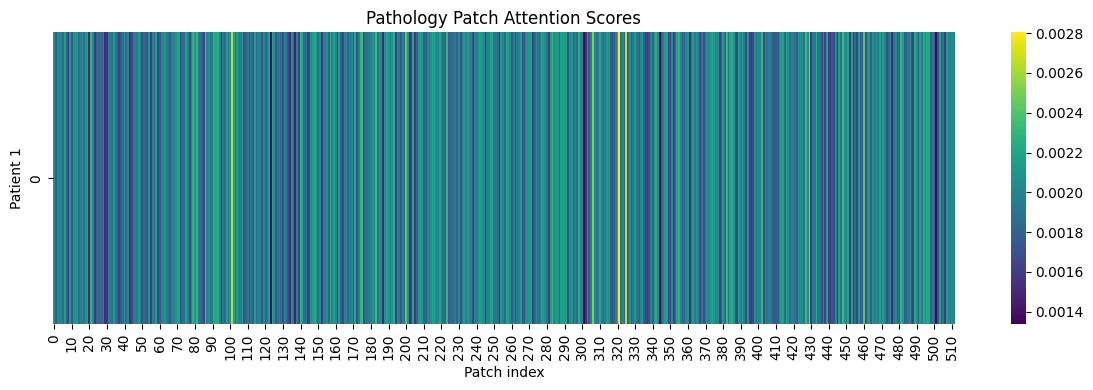

In [95]:
import seaborn as sns


plt.figure(figsize=(12,4))


sns.heatmap(
    pathology_attention_matrix.reshape(1,-1),
    cmap="viridis",
    cbar=True
)


plt.xlabel(
    "Patch index"
)

plt.ylabel(
    "Patient 1"
)


plt.title(
    "Pathology Patch Attention Scores"
)


plt.tight_layout()


plt.savefig(
    os.path.join(
        EXPLAIN_DIR,
        "pathology_patch_attention_heatmap.png"
    ),
    dpi=300
)


plt.show()

In [96]:
# ============================================================
# SAVE TOP PATHOLOGY PATCHES
# ============================================================


top_k = 20


scores = patch_attention[0].detach().cpu().numpy()


top_indices = np.argsort(
    scores
)[::-1][:top_k]


top_patch_df = pd.DataFrame({

    "Patch_Index":
    top_indices,


    "Attention_Score":
    scores[top_indices]

})


top_patch_path = os.path.join(
    EXPLAIN_DIR,
    "top_pathology_attention_patches.csv"
)


top_patch_df.to_csv(
    top_patch_path,
    index=False
)


print("="*70)
print("TOP PATHOLOGY PATCH TABLE SAVED")
print("="*70)


display(
    top_patch_df
)

TOP PATHOLOGY PATCH TABLE SAVED


,Patch_Index,Attention_Score
0,321,0.002804
1,101,0.002649
2,325,0.002649
3,429,0.002514
4,306,0.002514
5,200,0.002421
6,86,0.002420
7,460,0.002407
8,183,0.002340
9,283,0.002327


In [97]:
# ============================================================
# SAVE PATHOLOGY PATCH ATTENTION TABLE
# ============================================================


top_k = 20


# Select first patient attention scores
values = patch_attention[0]


# Get highest attention patches
top_indices = torch.argsort(
    values,
    descending=True
)[:top_k]


# Create dataframe
pathology_attention_df = pd.DataFrame({

    "Patch_Index":
    top_indices.detach().cpu().numpy(),

    "Attention_Score":
    values[top_indices].detach().cpu().numpy()

})


# Save CSV

pathology_attention_path = os.path.join(
    EXPLAIN_DIR,
    "pathology_top_patch_attention.csv"
)


pathology_attention_df.to_csv(
    pathology_attention_path,
    index=False
)


print("="*70)
print("PATHOLOGY PATCH ATTENTION TABLE SAVED")
print("="*70)

print(
    pathology_attention_path
)


display(
    pathology_attention_df
)

PATHOLOGY PATCH ATTENTION TABLE SAVED
/content/drive/MyDrive/TCGA_BRCA/explainability_results_v1/pathology_top_patch_attention.csv


,Patch_Index,Attention_Score
0,321,0.002804
1,101,0.002649
2,325,0.002649
3,306,0.002514
4,429,0.002514
5,200,0.002421
6,86,0.002420
7,460,0.002407
8,183,0.002340
9,283,0.002327
